# 0. Считываем файлы изображений в рабочей директории

In [31]:
import os
import numpy as np
from imageio import imread

In [24]:
working_directory = os.getcwd()  # Рабочая директория
images = [file for file in os.listdir(working_directory) if "jpg" in file]

In [25]:
images

['people.jpg', 'cars2.jpg', 'cars.jpg', 'elephants.jpg']

/tmp/ipykernel_2813/3046680459.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imread(image_name)


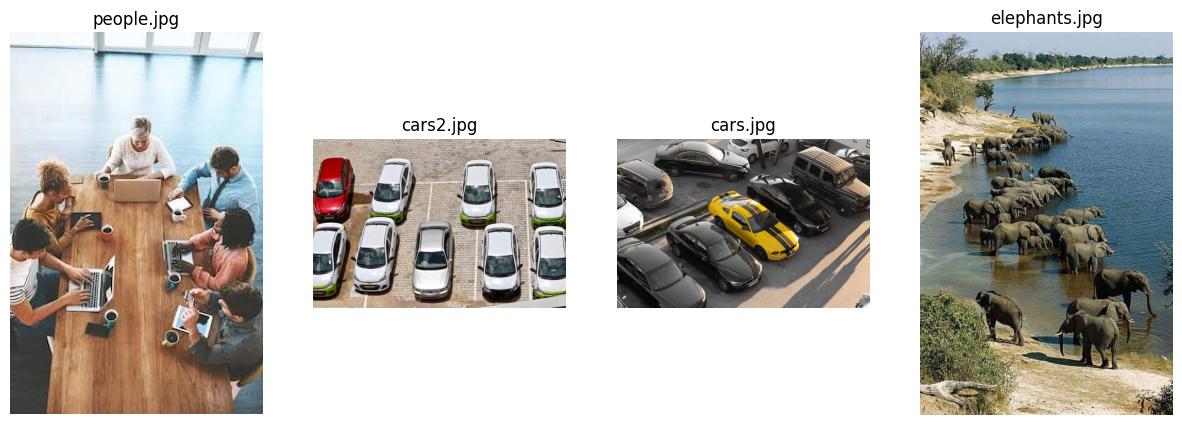

In [37]:
n_images = len(images)
fig = plt.figure(figsize = (15, 8))
for i in range(n_images):
    image_name = images[i]
    image = imread(image_name)
    fig.add_subplot(1, n_images, i+1)
    plt.title(image_name)
    plt.axis("off")
    plt.imshow(image)
plt.show()

# 1. Поиск и подсчет объектов: YOLO

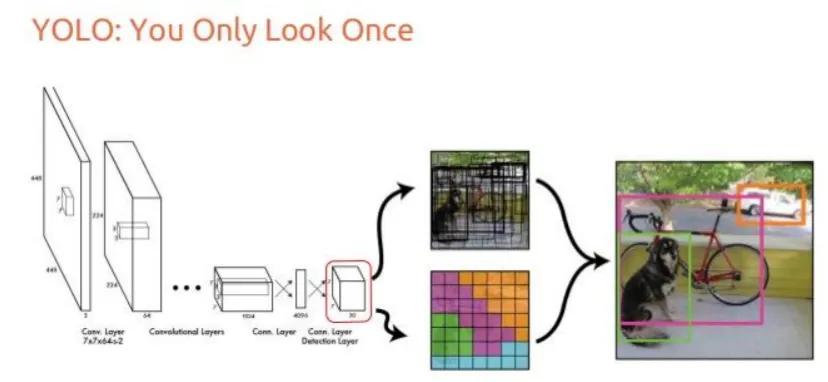

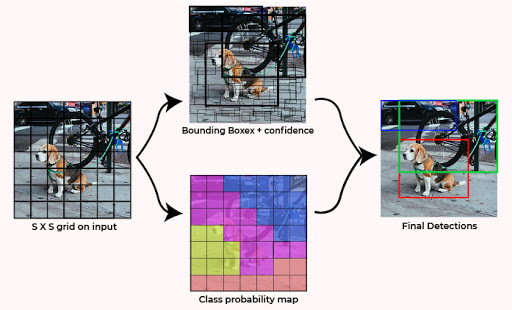

In [2]:
# !pip install ultralytics

In [8]:
from ultralytics import YOLO
from collections import Counter
import matplotlib.pyplot as plt

In [43]:
def count_objects(image_name):
  model = YOLO("yolo26n.pt")

  results = model.predict(
      source=image_name,
      conf=0.25,
  )

  result = results[0]
  class_ids = result.boxes.cls.int().tolist()
  counts = Counter(result.names[i] for i in class_ids)
  return result, counts, class_ids

def show_annotated_image(result):
  return result.plot()

In [42]:
for image_name in images:
  result, counts, class_ids = count_objects(image_name)
  print(counts)
  print("Всего объектов:", len(class_ids))


image 1/1 /content/people.jpg: 640x448 7 persons, 3 skateboards, 236.1ms
Speed: 8.9ms preprocess, 236.1ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 448)
Counter({'person': 7, 'skateboard': 3})
Всего объектов: 10

image 1/1 /content/cars2.jpg: 448x640 1 car, 7 cell phones, 171.2ms
Speed: 4.2ms preprocess, 171.2ms inference, 1.8ms postprocess per image at shape (1, 3, 448, 640)
Counter({'cell phone': 7, 'car': 1})
Всего объектов: 8

image 1/1 /content/cars.jpg: 448x640 10 cars, 1 truck, 176.3ms
Speed: 3.7ms preprocess, 176.3ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Counter({'car': 10, 'truck': 1})
Всего объектов: 11

image 1/1 /content/elephants.jpg: 640x448 9 elephants, 162.3ms
Speed: 4.0ms preprocess, 162.3ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 448)
Counter({'elephant': 9})
Всего объектов: 9



image 1/1 /content/people.jpg: 640x448 7 persons, 3 skateboards, 114.9ms
Speed: 3.0ms preprocess, 114.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 448)

image 1/1 /content/cars2.jpg: 448x640 1 car, 7 cell phones, 161.9ms
Speed: 2.5ms preprocess, 161.9ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /content/cars.jpg: 448x640 10 cars, 1 truck, 173.4ms
Speed: 4.2ms preprocess, 173.4ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)

image 1/1 /content/elephants.jpg: 640x448 9 elephants, 181.5ms
Speed: 4.3ms preprocess, 181.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 448)


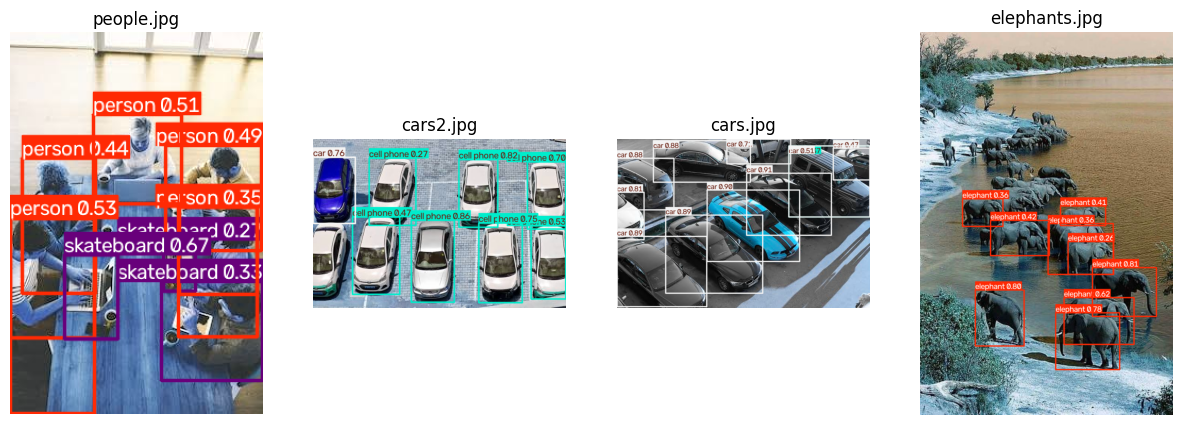

In [46]:
fig = plt.figure(figsize = (15, 8))
for i in range(n_images):
    image_name = images[i]
    result, _, _ = count_objects(image_name)
    annotated_image = show_annotated_image(result)
    fig.add_subplot(1, n_images, i+1)
    plt.title(image_name)
    plt.axis("off")
    plt.imshow(annotated_image)
plt.show()

# 2. Классификация без обучения (zero-shot classification): CLIP

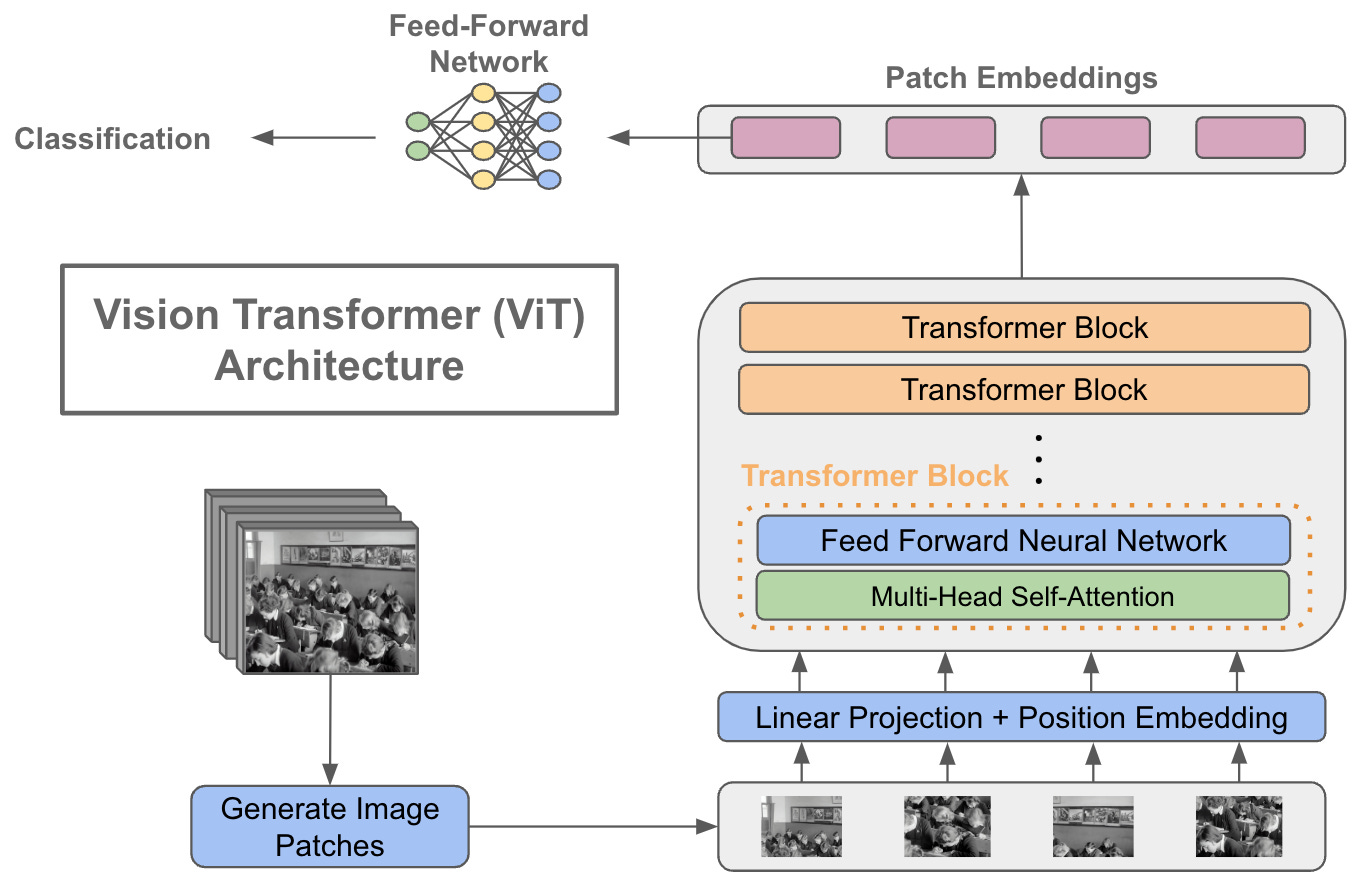

In [12]:
#pip install transformers torch pillow

In [ ]:
from transformers import pipeline

In [58]:
classifier = pipeline(
    task="zero-shot-image-classification",
    model="openai/clip-vit-large-patch14",
)

# candidate_labels = [
#         "a photo of people",
#         "a photo of cars",
#         "a photo of dogs",
#         "a photo of elephants",
#     ]

candidate_labels = [
        "a photo of people",
        "a photo of machinery",
        "a photo of animals",
        "a photo of utensils",
    ]

for image in images:
  results = classifier(image, candidate_labels=candidate_labels)
  print("\n=======")
  print(image, ":")
  for item in results:
      print(item["label"], round(item["score"], 3))

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]


people.jpg :
a photo of people 0.979
a photo of machinery 0.012
a photo of utensils 0.007
a photo of animals 0.003

cars2.jpg :
a photo of machinery 0.59
a photo of utensils 0.214
a photo of people 0.167
a photo of animals 0.029

cars.jpg :
a photo of machinery 0.923
a photo of animals 0.031
a photo of utensils 0.03
a photo of people 0.016

elephants.jpg :
a photo of animals 0.996
a photo of people 0.004
a photo of machinery 0.0
a photo of utensils 0.0


# 3. Поиск похожих изображений: DINOv2

In [59]:
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

In [62]:
model_name = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.eval()

def get_embedding(image_path):
    image = Image.open(image_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt")

    with torch.inference_mode():
        outputs = model(**inputs)

    # Эмбеддинг CLS-токена
    embedding = outputs.last_hidden_state[:, 0, :]

    return F.normalize(embedding, p=2, dim=1)

query_img = "cars.jpg"
query = get_embedding(query_img)
for candidate_img in images:
    if candidate_img == query_img:
        pass
    else:
        candidate = get_embedding(candidate_img)
        similarity = F.cosine_similarity(query, candidate).item()
        print(f"Image: {candidate_img}, Cosine similarity: {round(similarity, 4)}")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Image: people.jpg, Cosine similarity: 0.1176
Image: cars2.jpg, Cosine similarity: 0.7118
Image: elephants.jpg, Cosine similarity: 0.0379


# 4. Обнаружение объектов по текстовому запросу: Grounding DINO

In [51]:
import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

In [76]:
model_id = "IDEA-Research/grounding-dino-tiny"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id)

image = Image.open("people.jpg").convert("RGB")
#image = Image.open("cars2.jpg").convert("RGB")

# Какие объекты ищем
labels = [["notebooks", "mugs"]]
#labels = [["a red car"]]

inputs = processor(
    images=image,
    text=labels,
    return_tensors="pt",
)

with torch.inference_mode():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.35,
    text_threshold=0.25,
    target_sizes=[(image.height, image.width)],
)

for box, score, label in zip(
    results[0]["boxes"],
    results[0]["scores"],
    results[0]["text_labels"],
):
    print(
        label,
        round(score.item(), 3),
        [round(v, 1) for v in box.tolist()],
    )

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

mugs 0.699 [146.6, 226.1, 161.4, 244.0]
mugs 0.623 [87.6, 260.9, 102.4, 278.5]
mugs 0.643 [85.3, 181.3, 97.4, 198.3]
mugs 0.585 [81.9, 133.6, 94.3, 147.7]
notebooks 0.55 [143.2, 195.5, 174.2, 229.3]
mugs 0.535 [151.3, 165.9, 166.0, 180.2]
notebooks 0.495 [151.7, 257.1, 191.4, 289.6]
notebooks 0.533 [52.4, 210.2, 99.9, 264.7]
notebooks 0.466 [145.7, 154.2, 172.1, 170.2]
notebooks 0.51 [55.9, 169.1, 86.6, 187.1]


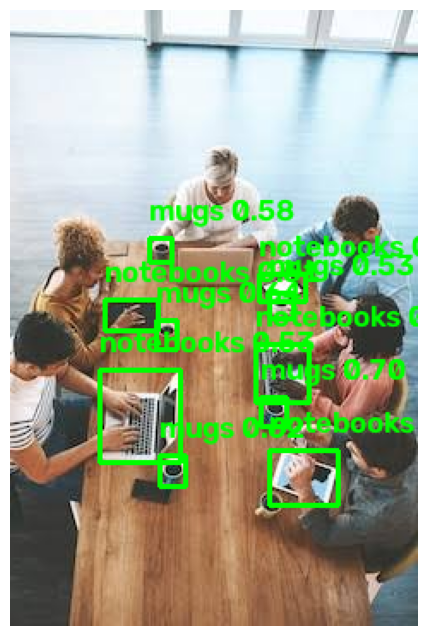

In [77]:
import cv2

# Draw bounding boxes manually (to illustrate mechanics)
image = np.array(Image.open("people.jpg").convert("RGB"))
#image = np.array(Image.open("cars2.jpg").convert("RGB"))
for (x1, y1, x2, y2), conf, cls in zip(results[0]["boxes"], results[0]["scores"], results[0]["text_labels"]):
    label = f"{cls} {conf:.2f}"
    cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0,255,0), 2)
    cv2.putText(image, label, (int(x1), int(y1)-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

plt.figure(figsize=(8,8))
plt.imshow(image)
plt.axis("off")
plt.show()

# 5. Задать вопрос по изображению: Qwen2.5-VL

In [ ]:
from transformers import pipeline

In [56]:
pipe = pipeline(
    task="image-text-to-text",
    model="Qwen/Qwen2.5-VL-3B-Instruct",
    device_map="auto",
)

image = Image.open("people.jpg").convert("RGB")

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": (
                    "Опиши изображение. "
                    "Какие объекты на нем видны?"
                ),
            },
        ],
    }
]

result = pipe(
    text=messages,
    max_new_tokens=120,
    return_full_text=False,
)

print(result[0]["generated_text"])

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

На изображении видны несколько людей, сидящих вокруг деревянного стола и работающих на ноутбуках. На столе также есть несколько чашек для кофе или чая. Видны также несколько ноутбуков, которые люди используют для работы.
